# Slow-wind state bias and high-speed decay terms (not built)

Variants added to the submitted linear model, refitted on the six yearly folds: state-dependent
bias terms, gating or dropping the current-sheet and X-ray terms in slow wind, a tighter
regressor cap, decay terms (fast hinge, speed trend) and the loss-weight blend.
Rule: > 1% better than the reference on >= 4 of 6 folds, slow runs not worse.
Study: `python -m training.slow_wind`; write-up `docs/slow_wind.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import model_diagnostics as dg
from training import slow_wind as sw

d = pd.read_csv(sw.EXPERIMENTS / "slow_wind.csv")
ref = d[d.variant == "reference"].set_index("fold")
regs = ["all", *dg.RUN_REGIMES]
for r in regs:
    d[f"{r} rel"] = d[r] / d.fold.map(ref[r])

def gm(s):
    return 100 * (np.exp(np.log(s).mean()) - 1)

summary = d.groupby("variant").agg(**{r: (f"{r} rel", gm) for r in regs})
summary["folds won"] = d.groupby("variant")["all rel"].apply(lambda s: int((s < 1).sum()))
summary.sort_values("all").round(2)

,all,CME,stream arrival,fast stream,intermediate,slow wind,folds won
variant,,,,,,,
cap 5%,-0.83,-0.11,-1.40,-2.88,-0.72,0.88,5
slope 24h x last,-0.12,-0.24,-0.10,-0.96,1.49,1.42,4
blend 0.2,-0.08,0.32,1.45,1.95,-1.85,-3.84,1
speed slope 24h,-0.07,-0.25,-0.09,-0.95,1.50,1.38,5
blend 0.15,-0.00,0.85,3.15,4.41,-3.81,-7.78,1
reference,0.00,0.00,0.00,0.00,0.00,0.00,0
slow indicator,0.02,0.23,-0.23,0.22,-0.56,1.31,3
hinge slow,0.03,0.30,-0.42,-0.78,-0.16,0.05,4
xray gated slow,0.04,0.07,0.06,0.07,-0.03,-0.02,2


## By fold (% vs reference)

In [2]:
(100 * (d.pivot(index="variant", columns="fold", values="all rel") - 1)).loc[
    summary.sort_values("all").index].round(2)

fold,2019,2020,2021,2022,2023,2024
variant,,,,,,
cap 5%,-0.65,-0.15,-2.69,-1.20,0.65,-0.94
slope 24h x last,-0.23,-0.05,-0.30,-0.92,0.00,0.80
blend 0.2,0.46,0.04,0.02,0.05,0.03,-1.09
speed slope 24h,-0.22,-0.08,-0.18,-0.86,-0.15,1.07
blend 0.15,1.09,0.29,0.21,0.26,0.19,-2.03
reference,0.00,0.00,0.00,0.00,0.00,0.00
slow indicator,0.64,-0.20,0.11,0.21,-0.07,-0.58
hinge slow,0.70,-0.02,-0.01,-0.33,0.19,-0.35
xray gated slow,0.04,0.05,0.19,-0.01,0.07,-0.12


## The blend trades slow wind against active wind

,all,CME,stream arrival,fast stream,intermediate,slow wind
0.10,0.31,1.69,5.20,7.66,-5.89,-11.92
0.15,-0.00,0.85,3.15,4.41,-3.81,-7.78
0.20,-0.08,0.32,1.45,1.95,-1.85,-3.84
0.25,0.00,0.00,0.00,0.00,0.00,0.00
0.35,0.54,-0.13,-2.42,-3.01,3.52,7.74


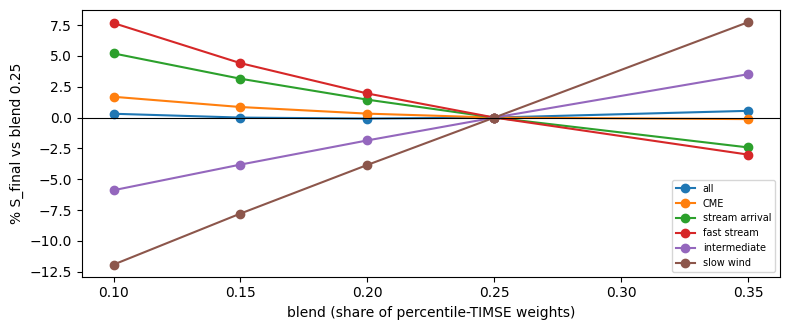

In [3]:
b = summary.loc[["blend 0.1", "blend 0.15", "blend 0.2", "reference", "blend 0.35"], regs]
b.index = [0.1, 0.15, 0.2, 0.25, 0.35]
ax = b.plot(marker="o", figsize=(8, 3.4))
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("blend (share of percentile-TIMSE weights)")
ax.set_ylabel("% S_final vs blend 0.25")
ax.legend(fontsize=7)
plt.tight_layout()
b.round(2)

Lowering the blend removes part of the upward lean: slow runs improve by up to 12%, but
CME, stream-arrival and fast runs lose as much, and the six-fold score is flat at 0.15–0.25.
Only the 2024 fold gains clearly. The slow-wind over-forecast is the price the official metric
asks for good active-wind forecasts, and blend 0.25 already balances it.

## The slow runs' mean residual (observed − forecast, km/s, mean over folds)

In [4]:
d.groupby("variant")["residual slow wind"].mean().sort_values().round(1)

variant
blend 0.35         -53.8
hinge slow         -48.1
slow indicator     -47.5
d_hcs gated slow   -47.4
hinges             -47.4
both gated slow    -46.8
reference          -46.6
slope 24h x last   -46.6
xray gated slow    -46.5
speed slope 24h    -46.5
speed slope 6h     -46.3
hinge fast         -46.0
cap 5%             -45.2
blend 0.2          -43.1
drop xray          -40.0
blend 0.15         -39.7
blend 0.1          -36.3
Name: residual slow wind, dtype: float64